# Varianza no es información

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 9, unidad 4 · Genera la figura de la lámina «El supuesto peligroso»

---

La clase afirma que PCA **no sabe qué es $y$**, y que por eso puede descartar
exactamente la dirección que discrimina si esa dirección tiene poca varianza.

Aquí se construye el caso y se mide. Y el resultado señala a un culpable
concreto: no a PCA, sino al criterio con que casi todo el mundo elige cuántas
componentes conservar.

## El diseño: un banco de sensores con modo común

Veinte sensores miden el mismo equipo. La estructura es la habitual en
instrumentación:

| Componente de la señal | Magnitud | ¿Informa sobre $y$? |
|---|---|---|
| **Modo común** — todos los sensores suben y bajan juntos con la carga del equipo | Enorme | **No** |
| Ruido independiente de cada sensor | Moderada | No |
| **Contraste** — la mitad de los sensores sube y la otra baja | **Pequeña** | **Sí** |

El modo común no dice nada del estado de la máquina: es la carga. Lo que
discrimina es el **desequilibrio** entre grupos de sensores, que es pequeño
comparado con la variación de carga.

PCA ordena por varianza, así que pondrá el modo común primero. Y el criterio
«conservar el 90 % de la varianza» conservará **solo eso**.

Nótese que esto ocurre **aunque se estandarice**, que es lo que la clase
recomienda: estandarizar iguala la varianza de cada *columna*, no la de cada
*dirección*.

## 1. Entorno

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)
print("matplotlib   ", matplotlib.__version__)

Python        3.12.14 | Darwin arm64
numpy         2.2.6
scikit-learn  1.9.0
matplotlib    3.10.9


In [2]:
SEMILLA = 9
N_CASOS = 600
N_SENSORES = 20
CARGA_MODO_COMUN = 6.0     # amplitud de la variación de carga, común a todos
DELTA_CONTRASTE = 0.30     # desequilibrio entre grupos según la clase

print(f"Sensores: {N_SENSORES}")
print(f"Modo común (sin información):  amplitud {CARGA_MODO_COMUN}")
print(f"Contraste (con información):   amplitud {DELTA_CONTRASTE}")
print(f"Razón de amplitudes: {CARGA_MODO_COMUN / DELTA_CONTRASTE:.0f} a 1")

Sensores: 20
Modo común (sin información):  amplitud 6.0
Contraste (con información):   amplitud 0.3
Razón de amplitudes: 20 a 1


## 2. Los datos

La etiqueta actúa **solo** sobre el contraste: la mitad de los sensores se
desplaza hacia arriba y la otra mitad hacia abajo. El modo común es independiente
de la clase.

In [3]:
rng = np.random.default_rng(SEMILLA)

y = rng.integers(0, 2, N_CASOS)

modo_comun = rng.standard_normal((N_CASOS, 1)) * CARGA_MODO_COMUN
X = modo_comun @ np.ones((1, N_SENSORES)) + rng.standard_normal((N_CASOS, N_SENSORES))

contraste = np.r_[np.ones(N_SENSORES // 2), -np.ones(N_SENSORES // 2)]
X += DELTA_CONTRASTE * (2 * y - 1)[:, None] * contraste[None, :]

print(f"X: {X.shape}   clases: {np.bincount(y)}")
print()
print(f"{'sensor':>8} {'varianza':>11} {'|corr. con y|':>16}")
print("-" * 38)
for j in [0, 1, 10, 11, 19]:
    c = abs(np.corrcoef(X[:, j], y)[0, 1])
    print(f"{j:>8} {X[:, j].var():>11.2f} {c:>16.3f}")
print()
print("Ningún sensor individual está muy correlacionado con la etiqueta:")
print("la información está en la DIFERENCIA entre grupos, no en ninguno por separado.")

X: (600, 20)   clases: [277 323]

  sensor    varianza    |corr. con y|
--------------------------------------
       0       34.94            0.099
       1       34.62            0.095
      10       34.06            0.021
      11       35.48            0.008
      19       34.10            0.008

Ningún sensor individual está muy correlacionado con la etiqueta:
la información está en la DIFERENCIA entre grupos, no en ninguno por separado.


## 3. Qué ordena PCA, y qué conserva el criterio del 90 %

In [4]:
X_estandarizado = StandardScaler().fit_transform(X)
pca_completo = PCA().fit(X_estandarizado)
var_exp = pca_completo.explained_variance_ratio_
acumulada = np.cumsum(var_exp)

print(f"{'componente':>11} {'varianza explicada':>20} {'acumulada':>12}")
print("-" * 46)
for k in list(range(4)) + [N_SENSORES - 1]:
    print(f"{k+1:>11} {var_exp[k]:>20.4f} {acumulada[k]:>12.4f}")

k_90 = int(np.searchsorted(acumulada, 0.90) + 1)
k_95 = int(np.searchsorted(acumulada, 0.95) + 1)
print()
print(f"Componentes para el 90 % de la varianza: {k_90} de {N_SENSORES}")
print(f"Componentes para el 95 % de la varianza: {k_95} de {N_SENSORES}")

 componente   varianza explicada    acumulada
----------------------------------------------
          1               0.9697       0.9697
          2               0.0042       0.9739
          3               0.0019       0.9758
          4               0.0018       0.9777
         20               0.0009       1.0000

Componentes para el 90 % de la varianza: 1 de 20
Componentes para el 95 % de la varianza: 1 de 20


**La primera componente sola explica más del 90 % de la varianza.** El criterio
habitual —«conserve las componentes que sumen el 90 %»— se queda con esa sola
componente, que es el modo común: exactamente lo que no informa.

## 4. Cuánto cuesta ese criterio

In [5]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

def evalua(tuberia):
    return cross_val_score(tuberia, X, y, cv=cv, scoring="accuracy").mean()

base = evalua(Pipeline([("esc", StandardScaler()),
                        ("clf", LogisticRegression(max_iter=3000))]))

ks = [1, 2, 3, 5, 10, 15, 20]
resultados = {k: evalua(Pipeline([("esc", StandardScaler()),
                                  ("pca", PCA(n_components=k)),
                                  ("clf", LogisticRegression(max_iter=3000))]))
              for k in ks}

lda = evalua(Pipeline([("esc", StandardScaler()),
                       ("lda", LinearDiscriminantAnalysis(n_components=1)),
                       ("clf", LogisticRegression(max_iter=3000))]))

print(f"{'representación':>40} {'dim.':>6} {'acierto':>9}")
print("-" * 58)
print(f"{'Sensores originales':>40} {N_SENSORES:>6} {base:>9.3f}")
for k in ks:
    marca = "   <- lo que conserva el criterio del 90 %" if k == k_90 else ""
    print(f"{'PCA':>40} {k:>6} {resultados[k]:>9.3f}{marca}")
print(f"{'LDA (mira la etiqueta)':>40} {1:>6} {lda:>9.3f}")

                          representación   dim.   acierto
----------------------------------------------------------
                     Sensores originales     20     0.927
                                     PCA      1     0.535   <- lo que conserva el criterio del 90 %
                                     PCA      2     0.933
                                     PCA      3     0.932
                                     PCA      5     0.928
                                     PCA     10     0.927
                                     PCA     15     0.923
                                     PCA     20     0.927
                  LDA (mira la etiqueta)      1     0.922


Los tres números que importan:

- **Sensores originales**: el desempeño de referencia.
- **PCA con 1 componente** —la que explica más del 90 % de la varianza—: apenas
  mejor que lanzar una moneda.
- **LDA con 1 componente**: prácticamente el desempeño completo.

**Misma dimensionalidad, resultados opuestos.** La diferencia no está en cuántas
dimensiones se conservan sino en **con qué criterio** se eligen: PCA maximiza
varianza y LDA maximiza separación entre clases.

Aviso importante: LDA **usa la etiqueta**, así que es entrenamiento y va dentro
del pliegue —como está aquí, en la tubería. Aplicarlo fuera sería la fuga de la
semana 7.

## 5. Figura

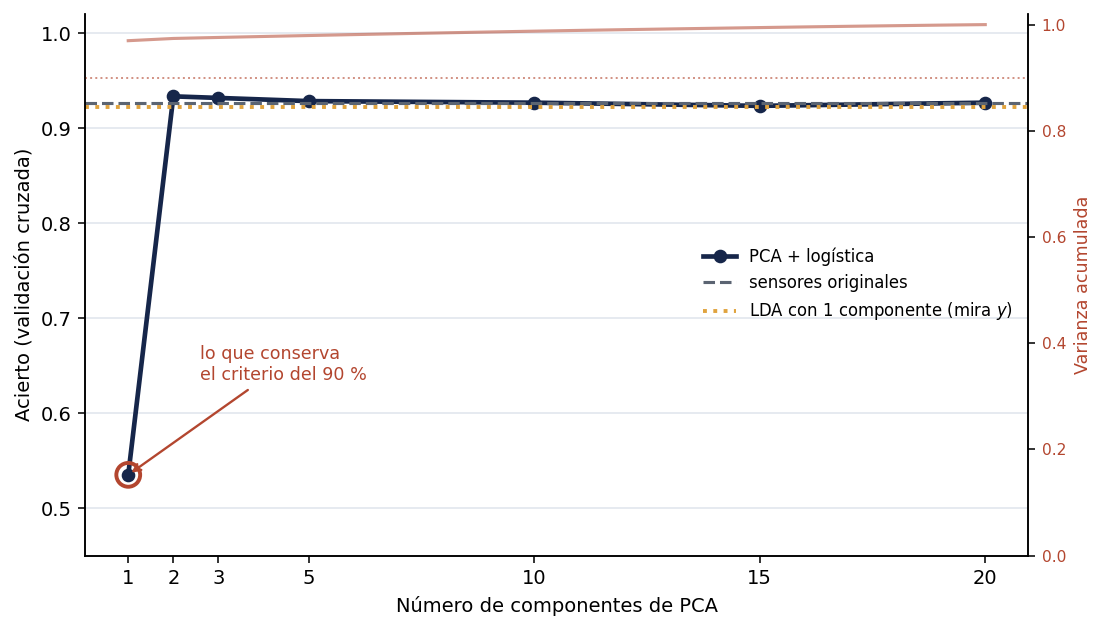

In [6]:
#| label: fig-pca
#| fig-cap: "Acierto según el número de componentes de PCA, frente a la varianza acumulada."
fig, ax = plt.subplots(figsize=(8, 4.6), dpi=140)

ax.plot(ks, [resultados[k] for k in ks], "o-", lw=2.4, ms=6,
        color="#16264A", label="PCA + logística")
ax.axhline(base, ls="--", lw=1.6, color="#5B6472", label="sensores originales")
ax.axhline(lda, ls=":", lw=2.0, color="#E0A33E",
           label="LDA con 1 componente (mira $y$)")
ax.scatter([k_90], [resultados[k_90]], s=150, facecolors="none",
           edgecolors="#B3462F", lw=2, zorder=5)
ax.annotate("lo que conserva\nel criterio del 90 %",
            xy=(k_90, resultados[k_90]), xytext=(2.6, resultados[k_90] + 0.10),
            fontsize=9, color="#B3462F",
            arrowprops=dict(arrowstyle="->", color="#B3462F", lw=1.2))

ax2 = ax.twinx()
ax2.plot(range(1, N_SENSORES + 1), acumulada, lw=1.6, color="#B3462F", alpha=0.55)
ax2.axhline(0.90, ls=":", lw=1, color="#B3462F", alpha=0.6)
ax2.set_ylabel("Varianza acumulada", color="#B3462F", fontsize=9)
ax2.tick_params(axis="y", labelcolor="#B3462F", labelsize=8)
ax2.set_ylim(0, 1.02)
ax2.spines[["top"]].set_visible(False)

ax.set_xlabel("Número de componentes de PCA")
ax.set_ylabel("Acierto (validación cruzada)")
ax.set_xticks(ks)
ax.set_ylim(0.45, 1.02)
ax.spines[["top"]].set_visible(False)
ax.grid(axis="y", color="#E6EAF0", lw=1); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8.5, loc="center right")

fig.tight_layout()
fig.savefig("pca_varianza_no_es_informacion.png", dpi=200, bbox_inches="tight")
plt.show()

La curva roja es la varianza acumulada, que salta al 90 % en la primera
componente y sugiere que con una basta. La curva azul es lo que importa, y en
esa primera componente está en su punto más bajo.

**Las dos curvas no coinciden, y esa es toda la lección.**

## 6. Estandarizar no es opcional, y tampoco es suficiente

Dos comprobaciones distintas y a menudo confundidas.

**Primera**: sin estandarizar, PCA mide unidades. Se reescala un sensor por mil
—como si se hubiera medido en otra unidad— y se mira a dónde apunta PC1.

In [7]:
X_unidades = X.copy()
X_unidades[:, 3] *= 1000.0

for nombre, datos, estandarizar in [
        ("Escala original, estandarizando",   X,          True),
        ("Escala original, SIN estandarizar", X,          False),
        ("Un sensor x1000, estandarizando",   X_unidades, True),
        ("Un sensor x1000, SIN estandarizar", X_unidades, False)]:
    D = StandardScaler().fit_transform(datos) if estandarizar else datos - datos.mean(0)
    p = PCA(n_components=1).fit(D)
    dominante = int(np.argmax(np.abs(p.components_[0])))
    print(f"{nombre:36s} var. PC1 {p.explained_variance_ratio_[0]:.3f}"
          f"   sensor dominante: {dominante:>2d}")

Escala original, estandarizando      var. PC1 0.970   sensor dominante: 11
Escala original, SIN estandarizar    var. PC1 0.970   sensor dominante: 14
Un sensor x1000, estandarizando      var. PC1 0.970   sensor dominante: 11
Un sensor x1000, SIN estandarizar    var. PC1 1.000   sensor dominante:  3


Sin estandarizar, PC1 **apunta al sensor reescalado** y explica casi toda la
varianza: el resultado no describe el fenómeno sino la unidad de medida. Con
estandarización, es invariante al cambio de unidades.

**Segunda, y es la que sorprende**: estandarizar **no** resuelve el problema de
este cuaderno. Todo el análisis anterior se hizo estandarizando, y aun así PC1
capturó el modo común e ignoró la señal.

La razón: estandarizar iguala la varianza de cada **columna**, no la de cada
**dirección**. El modo común sigue siendo la dirección de mayor varianza después
de estandarizar, porque los sensores están correlacionados entre sí. Son dos
problemas distintos y solo uno lo arregla la estandarización.

## 7. Bitácora

**Decisiones tomadas**

1. *Estructura de modo común más contraste.* Es la situación real de un banco de
   sensores: una variación global —carga, temperatura ambiente— que domina, y la
   información en el desequilibrio entre canales. Una primera versión de este
   cuaderno ponía la señal en dos **columnas** de varianza baja, y no funcionaba:
   al estandarizar, todas las columnas quedan con varianza uno y el orden que se
   había fabricado desaparece. **La construcción correcta exige que la señal viva
   en una dirección de baja varianza, no en una columna.** Vale la pena dejar
   constancia del error porque es exactamente la clase de detalle que invalida un
   experimento sin que nadie lo note.
2. *Razón de amplitudes de 20 a 1.* Suficiente para que PC1 supere por sí sola el
   90 % de la varianza, que es el umbral del criterio que se quiere criticar.
3. *Regresión logística como clasificador posterior.* Lineal, de modo que si la
   información está en un subespacio lineal la puede aprovechar. Con un modelo no
   lineal el resultado se confundiría con la capacidad del modelo para recuperar
   señal de mezclas.
4. *Comparación con LDA.* Es lo que convierte el cuaderno en un argumento y no en
   una queja contra PCA: con **la misma** dimensionalidad final, el criterio
   supervisado recupera casi todo. El problema no es reducir, es con qué criterio.
5. *Todo dentro de tuberías.* Escalado, PCA y LDA se reestiman en cada pliegue.
   LDA además mira la etiqueta, así que fuera del pliegue sería fuga.
6. *Acierto como métrica.* Las clases están balanceadas por construcción, así que
   aquí el acierto sí es interpretable. Con desbalance habría que usar lo de la
   semana 6.

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró usar un conjunto de datos real de alta dimensión. **Se descartó**
porque en datos reales no se sabe cuál es la dirección informativa, y entonces un
mal resultado de PCA admitiría dos explicaciones —que descartó la señal, o que no
había señal— sin forma de distinguirlas. Con datos construidos la afirmación es
verificable, que es lo que exige el ítem 8.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 8. Verificación

In [8]:
# 1. La primera componente sola supera el 90 % de la varianza.
assert acumulada[0] > 0.90, "PC1 debería superar por sí sola el 90 % de la varianza."
assert k_90 == 1

# 2. Y sin embargo es casi inútil para clasificar.
assert resultados[1] < 0.65, "PC1 debería discriminar muy poco."

# 3. Con la misma dimensionalidad, LDA recupera casi todo.
assert lda > resultados[1] + 0.25, "LDA con 1 componente debería superar ampliamente a PCA con 1."
assert lda > base - 0.05, "LDA debería acercarse al desempeño con todos los sensores."

# 4. Sin estandarizar, PC1 queda dominada por el sensor reescalado.
p_sin = PCA(n_components=1).fit(X_unidades - X_unidades.mean(0))
assert int(np.argmax(np.abs(p_sin.components_[0]))) == 3

print("Verificado:")
print(f"  - PC1 explica el {100*acumulada[0]:.1f} % de la varianza;")
print(f"  - PCA con 1 componente: acierto {resultados[1]:.3f};")
print(f"  - LDA con 1 componente: acierto {lda:.3f};")
print(f"  - sensores originales:  acierto {base:.3f};")
print("  - sin estandarizar, PC1 apunta al sensor de mayor escala.")

Verificado:
  - PC1 explica el 97.0 % de la varianza;
  - PCA con 1 componente: acierto 0.535;
  - LDA con 1 componente: acierto 0.922;
  - sensores originales:  acierto 0.927;
  - sin estandarizar, PC1 apunta al sensor de mayor escala.
